# Full NODDI Simulation and Nonlinear Least-Squares Fit

This notebook simulates full NODDI-style diffusion data with Watson orientation dispersion, fits the model with multi-start nonlinear least squares, and reports ODI from the fitted `kappa` parameter.

In [1]:
from pathlib import Path
import sys

def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "src").exists():
            return candidate
    raise RuntimeError("Could not locate repository root containing src/.")

repo_root = find_repo_root(Path.cwd().resolve())
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

import numpy as np
import matplotlib.pyplot as plt

from dmri_models import LeastSquaresFitter, noddi, noddi_derived_parameters, odi_from_kappa
from dmri_models.acquisitions import hcp
from dmri_models.acquisitions import rm_simple_epi
from dmri_models.compartments import WatsonFOD

rng = np.random.default_rng(11)

In [9]:
acquisition = rm_simple_epi()
preset = noddi(
    include_csf=True,
    fod_model="watson",
    vary_intracellular_diffusivity=False,
    vary_csf_diffusivity=False,
    vary_kappa=True,
    fod_quadrature_theta=20,
    fod_quadrature_phi=40,
)

model = preset.model
parameter_space = preset.parameters

true_parameters = parameter_space.initial_values()
true_parameters.update(
    {
        "S0": 1.0,
        "d_in": 2.2,
        "d_csf": 3.0,
        "kappa": 2.0,
        "theta": 1.0,
        "phi": 1.2,
        "neurite_fraction": 0.60,
        "extra_fraction": 0.30,
        "csf_fraction": 0.10,
    }
)

SNR=50
sigma = true_parameters["S0"]/SNR
signal_true = model.signal(acquisition, true_parameters)
signal_noisy = signal_true + rng.normal(0.0, sigma, size=signal_true.shape)

print(f"Measurements: {acquisition.n_measurements}")
print(f"Signal range: [{signal_true.min():.3f}, {signal_true.max():.3f}]")

Measurements: 620
Signal range: [0.077, 1.000]


In [10]:
fitter = LeastSquaresFitter(model, parameter_space)
fit = fitter.fit(
    acquisition,
    signal_noisy,
    n_starts=16,
    max_nfev=3000,
    rng=rng,
    initialise_orientation=True,
)

fit.parameters

{'S0': 0.9977391909691576,
 'd_in': 2.2,
 'theta': 0.9938852630330615,
 'phi': 1.199161501584695,
 'kappa': 2.0303700275852177,
 'd_csf': 3.0,
 'neurite_fraction': 0.6038708801455004,
 'extra_fraction': 0.3036477755676178,
 'csf_fraction': 0.09248134428688184}

In [11]:
ordered_names = [
    "S0",
    "d_in",
    "d_csf",
    "kappa",
    "theta",
    "phi",
    "neurite_fraction",
    "extra_fraction",
    "csf_fraction",
]

derived_true = noddi_derived_parameters(true_parameters)
derived_fit = noddi_derived_parameters(fit.parameters)

print(f"Success: {fit.success} | Cost: {fit.cost:.6f} | Evaluations: {fit.n_evaluations}")
print("\nParameter comparison (true vs fitted):")
for name in ordered_names:
    tv = true_parameters[name]
    fv = fit.parameters[name]
    err = fv - tv
    print(f"{name:16s} true={tv:8.4f}  fit={fv:8.4f}  error={err:+8.4f}")

print("\nDerived metrics:")
print(f"ODI true={derived_true['odi']:.4f}  fit={derived_fit['odi']:.4f}")
print(f"v_ic_tissue true={derived_true['v_ic_tissue']:.4f}  fit={derived_fit['v_ic_tissue']:.4f}")
print(f"ODI helper check (from fitted kappa): {odi_from_kappa(fit.parameters['kappa']):.4f}")

Success: True | Cost: 0.131314 | Evaluations: 15

Parameter comparison (true vs fitted):
S0               true=  1.0000  fit=  0.9977  error= -0.0023
d_in             true=  2.2000  fit=  2.2000  error= +0.0000
d_csf            true=  3.0000  fit=  3.0000  error= +0.0000
kappa            true=  2.0000  fit=  2.0304  error= +0.0304
theta            true=  1.0000  fit=  0.9939  error= -0.0061
phi              true=  1.2000  fit=  1.1992  error= -0.0008
neurite_fraction true=  0.6000  fit=  0.6039  error= +0.0039
extra_fraction   true=  0.3000  fit=  0.3036  error= +0.0036
csf_fraction     true=  0.1000  fit=  0.0925  error= -0.0075

Derived metrics:
ODI true=0.2952  fit=0.2913
v_ic_tissue true=0.6667  fit=0.6654
ODI helper check (from fitted kappa): 0.2913


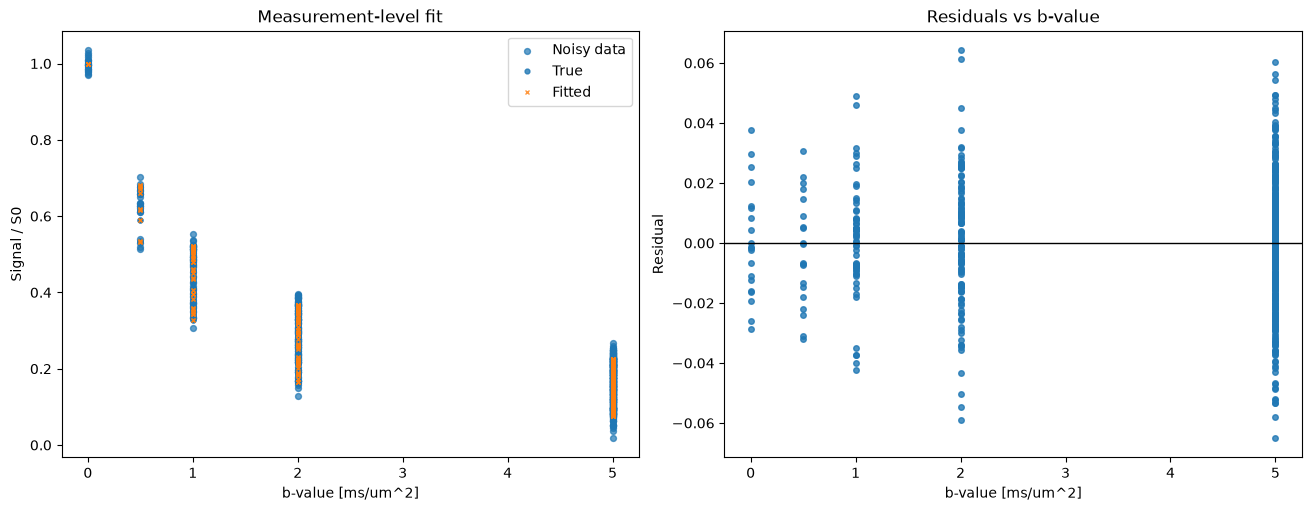

In [12]:
bvals = acquisition.b_values

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

axes[0].scatter(bvals, signal_noisy, s=18, alpha=0.7, label="Noisy data")
axes[0].plot(bvals, signal_true, "o", markersize=3.5, alpha=0.8, label="True")
axes[0].plot(bvals, fit.predicted_signal, "x", markersize=3.5, alpha=0.8, label="Fitted")
axes[0].set_xlabel("b-value [ms/um^2]")
axes[0].set_ylabel("Signal / S0")
axes[0].set_title("Measurement-level fit")
axes[0].legend()

residuals = signal_noisy - fit.predicted_signal
axes[1].scatter(bvals, residuals, s=16, alpha=0.8)
axes[1].axhline(0.0, color="k", linewidth=1)
axes[1].set_xlabel("b-value [ms/um^2]")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs b-value")

plt.show()

## Quadrature vs hypergeometric-ratio NODDI-style fit (Watson)

This section compares two mathematically equivalent routes to the same signal integral, and verifies they give consistent fitted parameters.

### The two pathways

**Quadrature convolution** (`FODConvolved` + `WatsonFOD`):

The Watson FOD is evaluated on a discrete spherical grid using Gauss-Legendre quadrature.  For each grid direction the oriented response (stick or zeppelin) is computed, and the signal is the weighted sum across directions.  This is general and works for any response/FOD combination.

**Hypergeometric-ratio** (`WatsonStickHypergeometric`, `WatsonZeppelinHypergeometric`):

The same spherical integral has a closed form as a ratio of normalising constants:

$$S_k = \frac{C(\mathbf{B} - b_k \beta_k \Delta d \cdot \mathbf{g}_k\mathbf{g}_k^\top)}{C(\mathbf{B})} \cdot e^{-b_k \, d_{\perp} (1 - \beta_k)/3}$$

where $C(\mathbf{Z}) = 4\pi \cdot {}_1F_1\!\left(\tfrac{1}{2}; \tfrac{3}{2}; \mathbf{Z}\right)$ is the Watson normalising constant (confluent hypergeometric function with matrix argument), and $\mathbf{B} = \kappa\,\boldsymbol{\mu}\boldsymbol{\mu}^\top$ is the Watson shape matrix built from concentration $\kappa$ and mean axis $\boldsymbol{\mu}$.

The key difference in the matrix argument between the two response types is:
- **Stick**: $\Delta d = d_{\parallel}$ (the full parallel diffusivity, since $d_{\perp} = 0$).
- **Zeppelin**: $\Delta d = d_{\parallel} - d_{\perp}$ (only the anisotropic part modulates orientation; the isotropic $d_{\perp}$ term is separated into the scalar prefactor).

Because both pathways implement the same mathematical object via the same quadrature grid, fitted parameters should agree to within quadrature discretisation error.

### Model setup for the comparison

To make the comparison strictly one-to-one, the extra-neurite compartment is a **Watson-convolved zeppelin** with a fixed `d_perp_ref` derived from the ground-truth tissue fractions (NODDI tortuosity: $d_{\perp} = d_{\parallel}(1 - v_{ic})$).  The fit uses a subsampled acquisition so it runs quickly in the notebook.

In [5]:
from dmri_models import Acquisition, Ball, Component, Model, Parameter, ParameterSpace, Simplex
from dmri_models.compartments import (
    FODConvolved,
    Stick,
    WatsonFOD,
    WatsonStickHypergeometric,
    WatsonZeppelinHypergeometric,
    Zeppelin,
)

# ── Ground-truth parameters ────────────────────────────────────────────────────
# We derive d_perp from the fractions using NODDI tortuosity:
#   v_ic = f_neurite / (1 - f_csf)   (intra-cellular fraction within tissue)
#   d_perp = d_in * (1 - v_ic)        (extra-axonal transverse diffusivity)
# This ensures the quadrature and hypergeometric models are generated from the
# same underlying geometry.
compare_true = {
    "S0": 1.0,
    "d_in": 2.0,     # um^2/ms  axial diffusivity (shared by stick and zeppelin)
    "d_csf": 3.0,    # um^2/ms  isotropic CSF diffusivity
    "kappa": 1.0,    # Watson concentration parameter (kappa=0 → isotropic, large → stick-like)
    "theta": 0.0,    # rad  polar angle of mean fibre axis
    "phi": 1.0,      # rad  azimuthal angle of mean fibre axis
    "neurite_fraction": 0.70,
    "extra_fraction":   0.20,
    "csf_fraction":     0.10,
}

# Derived fixed parameters (not fitted — held constant to make comparison clean).
compare_true["v_ic_tissue"] = (
    compare_true["neurite_fraction"] / (1.0 - compare_true["csf_fraction"])
)
compare_true["d_perp_ref"] = compare_true["d_in"] * (1.0 - compare_true["v_ic_tissue"])

# ── Subsampled acquisition ─────────────────────────────────────────────────────
# Use a small subset of the full HCP acquisition so both fits complete quickly.
# The comparison is about numerical equivalence, not fitting quality, so sample
# size is not critical here.
subset_size = 24
subset_idx = np.linspace(0, acquisition.n_measurements - 1, subset_size, dtype=int)

def _subset_field(values: np.ndarray | None) -> np.ndarray | None:
    if values is None:
        return None
    return np.asarray(values)[subset_idx]

acq_compare = Acquisition(
    b_values=np.asarray(acquisition.b_values)[subset_idx],
    gradients=_subset_field(acquisition.gradients),
    b_tensor_shape=_subset_field(acquisition.b_tensor_shape),
    pulse_duration=_subset_field(acquisition.pulse_duration),
    diffusion_time=_subset_field(acquisition.diffusion_time),
    gradient_strength=_subset_field(acquisition.gradient_strength),
    echo_time=_subset_field(acquisition.echo_time),
    inversion_time=_subset_field(acquisition.inversion_time),
    repetition_time=_subset_field(acquisition.repetition_time),
)

# ── Shared FOD object ─────────────────────────────────────────────────────────
# Both models use the same quadrature grid (n_theta × n_phi).  Using the same
# grid for both quadrature and hypergeometric ensures any residual difference is
# purely from the implementation pathway, not from a resolution mismatch.
fod = WatsonFOD(kappa="kappa", theta="theta", phi="phi", n_theta=8, n_phi=16)

# ── Pathway 1: quadrature convolution ─────────────────────────────────────────
# FODConvolved iterates over the quadrature directions and accumulates the
# weighted sum of oriented response signals.
# The Zeppelin uses d_perp_ref as its transverse diffusivity (fixed scalar).
quadrature_model = Model(
    [
        Component(
            "neurite",
            FODConvolved(
                response=Stick(diffusivity="d_in", orientation="axis"),
                fod=fod,
                orientation_parameter="axis",
            ),
        ),
        Component(
            "extra",
            FODConvolved(
                # Zeppelin argument:  delta_d = d_in - d_perp_ref
                # The hypergeometric ratio pathway uses this same delta_d.
                response=Zeppelin(
                    parallel_diffusivity="d_in",
                    perpendicular_diffusivity="d_perp_ref",
                    orientation="axis",
                ),
                fod=fod,
                orientation_parameter="axis",
            ),
        ),
        Component("csf", Ball(diffusivity="d_csf")),
    ]
)

# ── Pathway 2: hypergeometric ratio ───────────────────────────────────────────
# Each signal is computed as C(B - b·β·Δd·ggᵀ) / C(B), where:
#   B      = κ·μμᵀ  (Watson shape matrix)
#   C(Z)   = 4π·₁F₁(1/2; 3/2; Z)  (normalising constant via matrix hyp. function)
#   Δd     = d_in           for WatsonStickHypergeometric (d_perp=0 for a stick)
#   Δd     = d_in - d_perp  for WatsonZeppelinHypergeometric (anisotropic part only)
# The isotropic d_perp contribution is separated as exp(-b·d_perp·(1-β)/3).
hyper_model = Model(
    [
        Component(
            "neurite",
            WatsonStickHypergeometric(
                diffusivity="d_in",          # Δd = d_in (full, since stick has d_perp=0)
                kappa="kappa",
                theta="theta",
                phi="phi",
                n_theta=8,
                n_phi=16,
            ),
        ),
        Component(
            "extra",
            WatsonZeppelinHypergeometric(
                parallel_diffusivity="d_in",
                perpendicular_diffusivity="d_perp_ref",  # Δd = d_in - d_perp_ref
                kappa="kappa",
                theta="theta",
                phi="phi",
                n_theta=8,
                n_phi=16,
            ),
        ),
        Component("csf", Ball(diffusivity="d_csf")),
    ]
)

# ── Shared parameter space ────────────────────────────────────────────────────
# d_in, d_perp_ref, d_csf are fixed so they don't confound the comparison.
# kappa, theta, phi, and the fractions are free.
compare_space = ParameterSpace(
    [
        Parameter("S0",        compare_true["S0"],        (0.05, 2.0)),
        Parameter("d_in",      compare_true["d_in"],      (0.5, 3.0),  vary=False),
        Parameter("d_perp_ref",compare_true["d_perp_ref"],(0.0, 3.0),  vary=False),
        Parameter("d_csf",     compare_true["d_csf"],     (1.5, 3.5),  vary=False),
        Parameter("kappa",     compare_true["kappa"],     (0.0, 64.0), vary=True),
        Parameter("theta",     compare_true["theta"],     (0.0, np.pi),vary=True),
        Parameter("phi",       compare_true["phi"],       (-np.pi, np.pi), vary=True),
    ],
    simplexes=[Simplex(("neurite_fraction", "extra_fraction", "csf_fraction"), (0.6, 0.3, 0.1))],
)

# ── Simulate data from the quadrature model (ground truth) ────────────────────
# Both models are fitted to the same noisy data so the comparison is fair.
compare_sigma = compare_true["S0"] / SNR
compare_signal_true  = quadrature_model.signal(acq_compare, compare_true)
compare_signal_noisy = compare_signal_true + rng.normal(
    0.0, compare_sigma, size=compare_signal_true.shape
)

# ── Fit both models ───────────────────────────────────────────────────────────
# n_starts=10 with the modest budget is enough to compare convergence behaviour.
fit_quad = LeastSquaresFitter(quadrature_model, compare_space).fit(
    acq_compare,
    compare_signal_noisy,
    n_starts=10,
    max_nfev=250,
    rng=rng,
)

fit_hyp = LeastSquaresFitter(hyper_model, compare_space).fit(
    acq_compare,
    compare_signal_noisy,
    n_starts=10,
    max_nfev=250,
    rng=rng,
)

# ── Report ─────────────────────────────────────────────────────────────────────
names = ["S0", "kappa", "theta", "phi", "neurite_fraction", "extra_fraction", "csf_fraction"]

print("Quadrature vs hypergeometric-ratio fit comparison (subsampled acquisition)")
print(f"Measurements used: {acq_compare.n_measurements}")
print(f"quadrature: success={fit_quad.success}, cost={fit_quad.cost:.6f}")
print(f"hypergeom : success={fit_hyp.success}, cost={fit_hyp.cost:.6f}")

print()
print(f"{'Parameter':>20}  {'Quadrature':>12}  {'Hypergeom':>12}  {'Delta':>12}")
print("-" * 62)
for key in names:
    qv = fit_quad.parameters[key]
    hv = fit_hyp.parameters[key]
    print(f"{key:>20}  {qv:>12.6f}  {hv:>12.6f}  {hv - qv:>+12.2e}")

# The max absolute difference between predicted signals is the most informative
# summary: it measures agreement in signal space regardless of parameter symmetry.
prediction_delta = np.max(np.abs(fit_hyp.predicted_signal - fit_quad.predicted_signal))
print()
print(f"Max |pred_hyp - pred_quad| = {prediction_delta:.3e}")
print("(Should be close to machine precision if quadrature resolution is sufficient.)")

Quadrature vs hypergeometric-ratio fit comparison (subsampled acquisition)
Measurements used: 24
quadrature: success=True, cost=0.002696
hypergeom : success=True, cost=0.002696

           Parameter    Quadrature     Hypergeom         Delta
--------------------------------------------------------------
                  S0      1.013260      1.013260     +1.63e-09
               kappa      0.901715      0.901715     -1.64e-08
               theta      2.972619      2.972619     +1.05e-08
                 phi      2.750399      2.750399     +1.44e-08
    neurite_fraction      0.693633      0.693633     +1.37e-08
      extra_fraction      0.217977      0.217977     -3.19e-08
        csf_fraction      0.088390      0.088390     +1.82e-08

Max |pred_hyp - pred_quad| = 4.299e-09
(Should be close to machine precision if quadrature resolution is sufficient.)
